# Tutorial: computing the polarization degree of synchrotron radiation
In this tutorial, we will show how to compute the polarization degree of the synchrotron radiation emitted by a blob using `agnpy`.  
The implementation relies on [Rybicki&Lightman1989](https://ui.adsabs.harvard.edu/abs/1979rpa..book.....R/abstract) and [DermerMenon2009](https://ui.adsabs.harvard.edu/abs/2009herb.book.....D/abstract).

In [10]:
# import numpy, astropy and matplotlib for basic functionalities
import numpy as np
from astropy import units as u
from astropy.constants import m_e, m_p
from astropy.table import QTable
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, jet
import pkg_resources

# import agnpy classes
from agnpy.emission_regions import Blob
from agnpy.spectra import PowerLaw, BrokenPowerLaw, LogParabola
from agnpy.synchrotron import Synchrotron, ProtonSynchrotron
from agnpy.utils.plot import plot_sed, load_mpl_rc

load_mpl_rc()

We first consider a population of relativistic electrons following a power-law with spectral index $p$, namely $\frac{dN}{d\gamma}\propto\gamma^{-p}$. The linear polarization degree of the synchrotron emission is expected to be

$\Pi_{\nu, \text{PL}}= \frac{p+1}{p+7/3}$

Here we consider a blob whose electron spectrum is described by a power law with indices $p=1.5, 2.0, 2.5, 3.0$, and we compute its synchrotron SED and polarization degree.

In [2]:
def polarization_degree_power_law (p):
    return (p + 1) / (p + 7/3)

In [3]:
nu = np.logspace(8, 20, 300) * u.Hz

agnpy_tab = QTable()
agnpy_tab["nu"] = nu

R_b = 2.5e16 * u.cm
B = 6.5e-2 * u.G
Gamma = 15.0
theta = 1.35 * u.Unit("deg")
Beta = np.sqrt(1 - 1/Gamma**2)
delta_D = 1 / (Gamma * (1 - Beta * np.cos(theta.to_value("rad"))))
z = 0.2
N = 1.2 * u.Unit('cm-3')
gamma_min = 50
gamma_max = 8e5

spectral_indices = [1.50, 2.00, 2.50, 3.00]

for p in spectral_indices:
    n_e = PowerLaw.from_total_density(
        N, p = p, gamma_min = gamma_min, gamma_max = gamma_max, mass = m_e
    )
    blob = Blob(n_e = n_e, R_b = R_b, z = z, B = B, delta_D = delta_D, Gamma = Gamma,)
    synch = Synchrotron(blob, ssa = False)
    agnpy_tab[f'nuFnu (p={p:.1f})'] = synch.sed_flux(nu)
    agnpy_tab[f'pol_deg (p={p:.1f})'] = synch.polarization_degree(nu)

For validation, we will compare the synchrotron SED and polarization computed with `agnpy` with those computed with `jetset` v1.3.0.  
These are stored in the file `agnpy/data/reference_seds/jetset/data/synch_polarization_jetset_1.3.0.ecsv`, which can be created by running `agnpy/data/reference_seds/jetset/jetset_synch_polarization.py` (both `agnpy` and `jetset` are required).

In [4]:
sed_path = pkg_resources.resource_filename(
    "agnpy",
    "data/reference_seds/jetset/data/synch_polarization_jetset_1.3.0.ecsv"
)
jetset_tab = QTable.read(sed_path, format="ascii.ecsv")
nu = jetset_tab["nu"]
print(list(jetset_tab.columns))

['nu', 'nuFnu (p=1.5)', 'pol_deg (p=1.5)', 'nuFnu (p=2.0)', 'pol_deg (p=2.0)', 'nuFnu (p=2.5)', 'pol_deg (p=2.5)', 'nuFnu (p=3.0)', 'pol_deg (p=3.0)']


In [5]:
np.allclose(
    agnpy_tab["nu"].to_value("Hz"), 
    jetset_tab["nu"].to_value("Hz"),
    rtol = 1e-6,
)

True

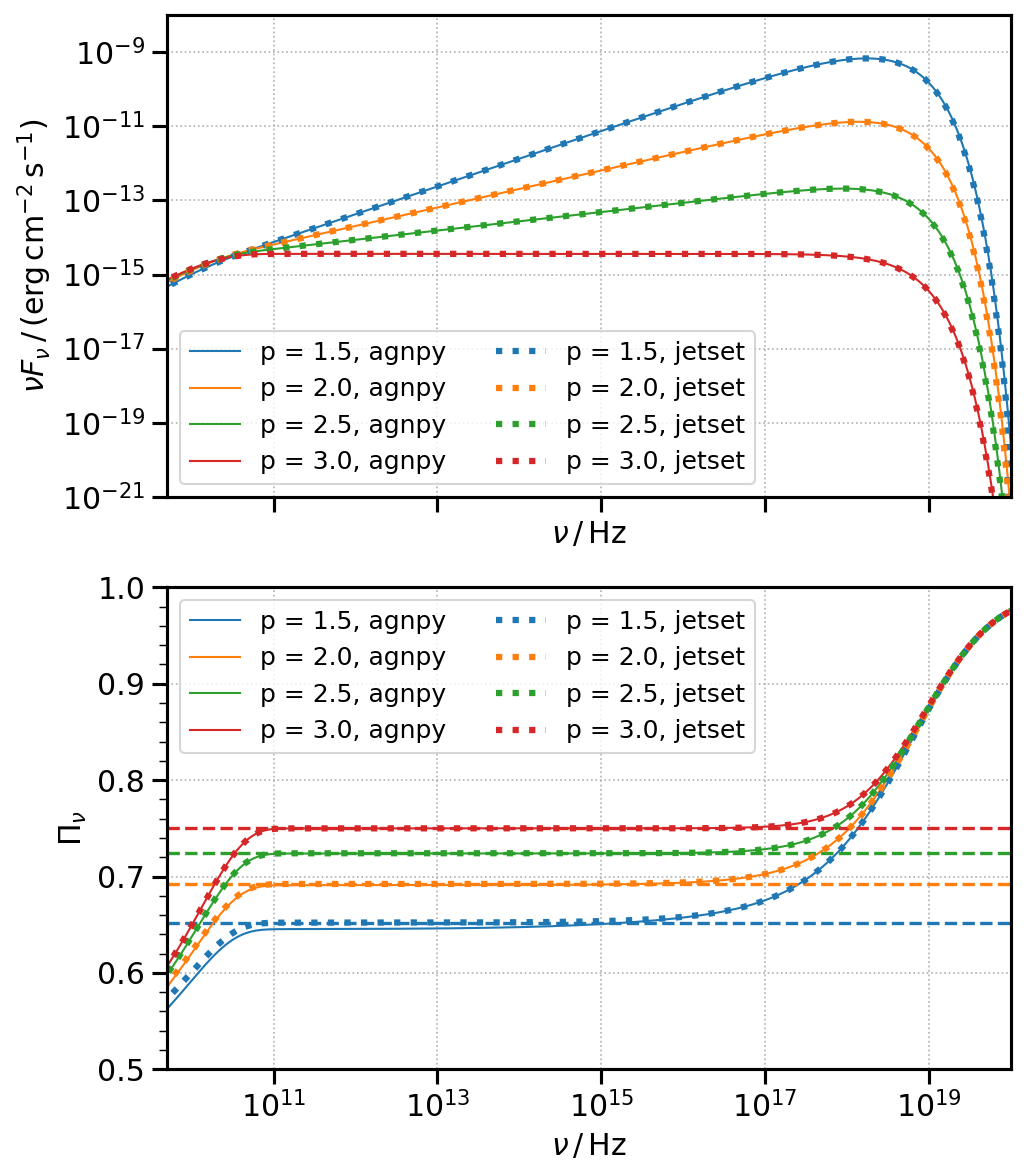

In [6]:
fig, axs = plt.subplots(2, 1, figsize = (7, 8), sharex = True)

codes = ["agnpy", "jetset"]
tabs = [agnpy_tab, jetset_tab]
lss = ["solid", "dotted"]
lws = [1, 3]

for j in range(len(codes)):

    for i_p, p in enumerate(spectral_indices):

        tab = tabs[j]
        code = codes[j]
        label = f'p = {p:.1f}, {code}'
        color = f"C{i_p}"
        kwargs = {"label":label, "color":color, "ls":lss[j], "lw":lws[j]}

        ax = axs[0]
        plot_sed(
            tab[f'nu'], 
            tab[f'nuFnu (p={p:.1f})'], 
            ax = ax, **kwargs
        );

        ax = axs[1]
        ax.plot(
            tab[f'nu'],
            tab[f'pol_deg (p={p:.1f})'],
            **kwargs
        )

        if j == 0:
            ax.axhline(polarization_degree_power_law(p), 
                       ls = 'dashed', color = color)

axs[1].set_xlabel(axs[0].get_xlabel())
axs[1].set_ylabel("$\\Pi_{\\nu}$")
axs[1].set_xscale("log")
axs[1].set_xlim(5e9, 1e20)
axs[1].set_ylim(0.5, 1.0)
axs[0].set_ylim(1e-21, 1e-8)
for ax in axs:
    ax.legend(ncols = 2)


This plot shows that the polarization degree $\Pi_\nu$ for a power-law distribution of electrons is compatible with the analytical formula $\Pi_{\nu, \text{PL}}(p)$ for most of the energy range, while tending to $100\%$ at the highest energies of the energy spectrum.

We now compute the synchrotron polarization degree for electron energy distributions modeled with analytical functions different from the power-law, such as a broken power-law and a log-parabola.

For the case of the broken power-law with indices $p_1$ and $p_2$, the synchrotron polarization degree shows a transition between the two $\Pi_{\nu, \text{PL}}(p_1)$ and $\Pi_{\nu, \text{PL}}(p_2)$ values.

In [7]:
# Broken power law
p1, p2 = 2.6, 3.7
bpl = BrokenPowerLaw(p1 = p1, p2 = p2, gamma_b = 2000, gamma_min = 10, gamma_max = 1e5)
blob_bpl = Blob(n_e = bpl, R_b = R_b, z = z, B = B, delta_D = delta_D)
synch_bpl = Synchrotron(blob_bpl, ssa = False)
pol_degree_bpl = synch_bpl.polarization_degree(nu)

/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


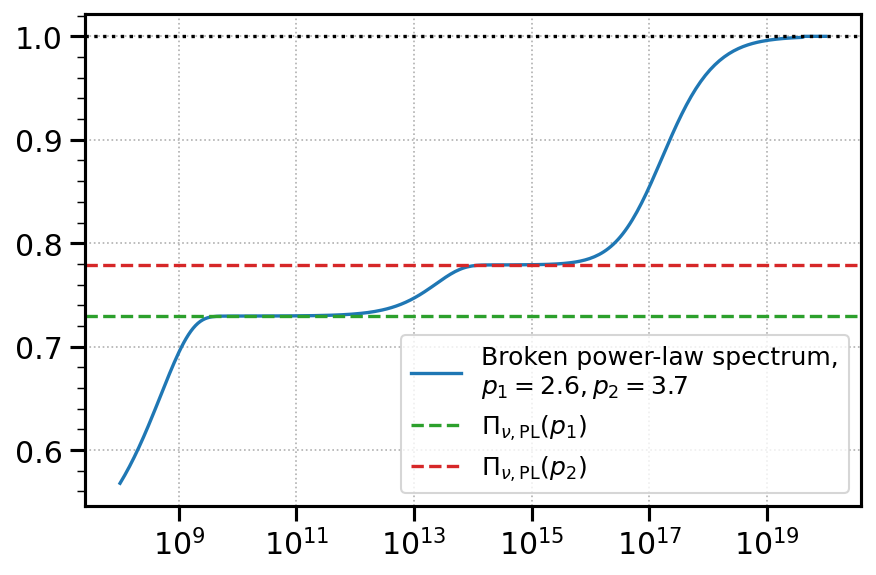

In [8]:
fig, ax = plt.subplots(figsize = (6, 4))
ax.plot(nu, pol_degree_bpl, label = f"Broken power-law spectrum,\n$p_1={p1}, p_2={p2}$")
ax.set_xscale("log")
ax.axhline(polarization_degree_power_law(p1), linestyle='--', label = r"$\Pi_{\nu,\mathrm{PL}}(p_1)$", color = "C2")
ax.axhline(polarization_degree_power_law(p2), linestyle='--', label = r"$\Pi_{\nu,\mathrm{PL}}(p_2)$", color = "C3")
ax.axhline(1, ls='dotted', color = "black")
ax.legend()

In [9]:
# LogParabola
p, q = 2.2, 0.6
lp = LogParabola(p = p, q = q, gamma_0 = 1e3, gamma_min = 10, gamma_max = 1e5)
blob_lp = Blob(n_e = lp, R_b = R_b, z = z, B = B, delta_D = delta_D)
synch_lp = Synchrotron(blob_lp, ssa = False)
pol_degree_lp = synch_lp.polarization_degree(nu)

/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


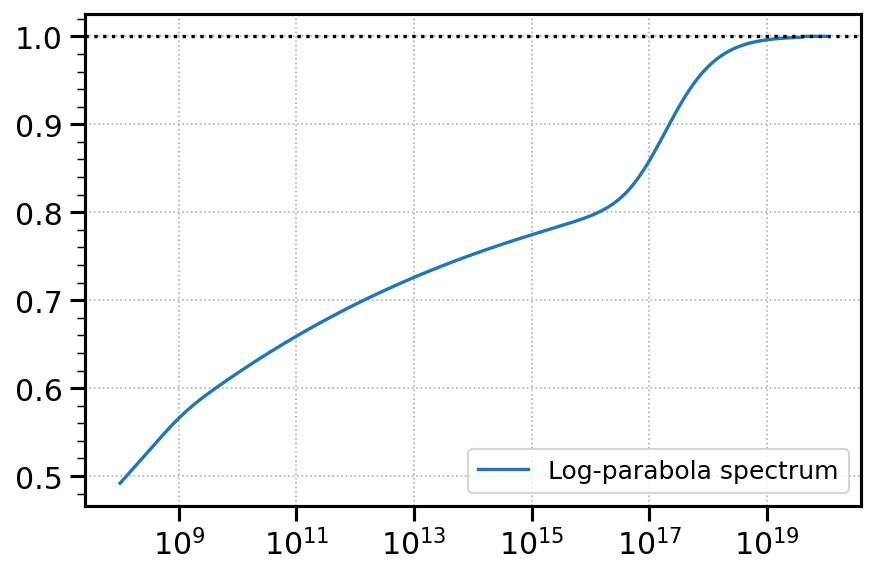

In [10]:
fig, ax = plt.subplots(figsize = (6, 4))
ax.plot(nu, pol_degree_lp, label = f"Log-parabola spectrum")
ax.set_xscale("log")
ax.axhline(1, ls='dotted', color = "black")
ax.legend()

We now show how to compute the synchrotron polarization degree for a power-law distribution of relativistic protons.

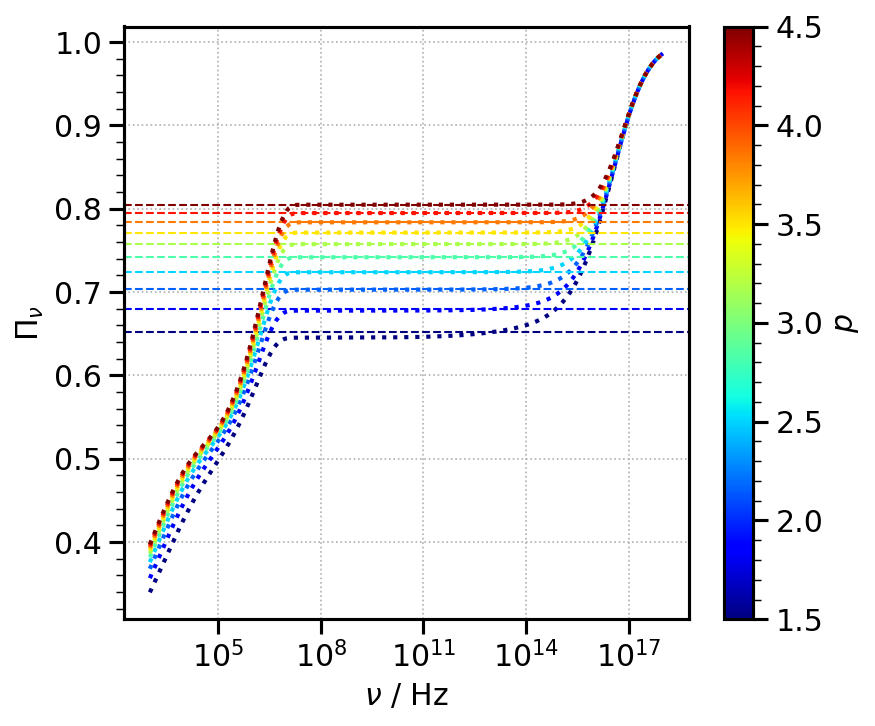

In [11]:
p_min, p_max = 1.5, 4.5
p_vals = np.linspace(p_min, p_max, 10)

fig, ax = plt.subplots(figsize = (6, 5))

norm = Normalize(vmin = p_min, vmax = p_max)
cmap = jet
sm = ScalarMappable(norm=norm, cmap=cmap)

for p in p_vals:
    n_p = PowerLaw.from_total_density(
        1.0 * u.Unit("cm-3"), p=p, gamma_min=10, gamma_max=1e6, mass=m_p
    )
    blob = Blob(n_p=n_p)
    nu = np.logspace(3, 18, 200) * u.Hz
    synch = ProtonSynchrotron(blob)
    pol_degree = synch.polarization_degree(nu)

    color = cmap(norm(p))
    ax.plot(nu, pol_degree, lw = 2, color = color, ls = "dotted")
    ax.axhline(polarization_degree_power_law(p), ls = "dashed", lw = 1, color = color)

ax.set_xlabel("$\\nu$ / Hz")
ax.set_ylabel("$\\Pi_{\\nu}$")
cbar = fig.colorbar(sm, ax = ax)
cbar.set_label("$p$")
ax.set_xscale("log")

plt.show();